# B09 故障很少时，怎样避免模型只预测正常？

在模拟设备数据上区分模型评分、概率校准与行动阈值。校准只用训练数据的交叉验证，阈值只用验证集，以错误成本选型后锁定测试。

先修：B08；混淆矩阵、概率、阈值与验证集。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 制造有少数故障的可检查数据
随机生成 8 个传感器特征，故障约占 8%。真实设备可能存在时间与设备分组，此处是假设独立样本的教学实验。用分层划分保证各段都有故障。

In [2]:
import numpy as np, pandas as pd, json
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import confusion_matrix, precision_score, recall_score, brier_score_loss
X, y = make_classification(n_samples=1800, n_features=8, n_informative=5, weights=[0.92,0.08], class_sep=1.3, flip_y=0.01, random_state=9)
X_train, X_hold, y_train, y_hold = train_test_split(X,y,test_size=0.4,stratify=y,random_state=9)
X_val, X_test, y_val, y_test = train_test_split(X_hold,y_hold,test_size=0.5,stratify=y_hold,random_state=9)
pd.DataFrame(X,columns=[f'sensor_{i}' for i in range(8)]).assign(failure=y).to_csv(DATA_DIR/'simulated_devices.csv',index=False)


## 2. 训练与概率校准分开理解
带类别权重的模型更关注少数类，但原始概率不应直接当真实故障率。用训练折内 sigmoid 校准得到候选概率，测试集始终不参与拟合。Brier 分数评价概率误差。

In [3]:
raw_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced',max_iter=500,random_state=9))
raw_model.fit(X_train,y_train)
calibrated = CalibratedClassifierCV(make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced',max_iter=500,random_state=9)), method='sigmoid', cv=3)
calibrated.fit(X_train,y_train)
p_val = calibrated.predict_proba(X_val)[:,1]
p_test = calibrated.predict_proba(X_test)[:,1]


## 3. 阈值对应明确代价
漏检一次成本假定 20，误报一次成本假定 1。扫描验证阈值，输出误报、漏报与总成本。阈值小通常更积极报警，但最终应看当前成本和容量条件。

In [4]:
def error_cost(truth, pred, missed=20, false_alarm=1):
    tn, fp, fn, tp = confusion_matrix(truth,pred,labels=[0,1]).ravel()
    return {'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),'cost':float(missed*fn+false_alarm*fp)}
threshold_rows = []
for threshold in np.linspace(0.01,0.8,80):
    threshold_rows.append({'threshold':float(threshold), **error_cost(y_val,p_val>=threshold)})
threshold_table = pd.DataFrame(threshold_rows)
threshold = float(threshold_table.loc[threshold_table['cost'].idxmin(),'threshold'])
pred = p_test >= threshold


## 4. 在测试集报告代价与可靠性
校准曲线每组的横轴是平均预测概率，纵轴是真实故障率；样本少时曲线会抖动。不能以准确率单独评判故障模型，也不能保证校准在分布变化后仍有效。

In [5]:
metrics = {'selected_threshold':threshold,'all_normal':error_cost(y_test,np.zeros_like(y_test)), 'threshold_0_5':error_cost(y_test,p_test>=0.5), 'selected':error_cost(y_test,pred), 'precision':float(precision_score(y_test,pred,zero_division=0)), 'recall':float(recall_score(y_test,pred,zero_division=0)), 'raw_brier':float(brier_score_loss(y_test,raw_model.predict_proba(X_test)[:,1])), 'calibrated_brier':float(brier_score_loss(y_test,p_test))}
threshold_table.to_csv(OUT_DIR/'threshold_validation.csv',index=False)
pd.DataFrame({'actual':y_test,'probability':p_test,'alert':pred}).to_csv(OUT_DIR/'predictions.csv',index=False)
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
fraction, average = calibration_curve(y_test,p_test,n_bins=6,strategy='quantile')
plt.plot(average,fraction,'o-',label='校准模型'); plt.plot([0,1],[0,1],'--'); plt.xlabel('平均预测概率'); plt.ylabel('实际故障比例'); plt.legend(); plt.tight_layout(); plt.savefig(OUT_DIR/'calibration.png'); plt.close(); print(metrics)


{'selected_threshold': 0.060000000000000005, 'all_normal': {'tn': 330, 'fp': 0, 'fn': 30, 'tp': 0, 'cost': 600.0}, 'threshold_0_5': {'tn': 328, 'fp': 2, 'fn': 14, 'tp': 16, 'cost': 282.0}, 'selected': {'tn': 247, 'fp': 83, 'fn': 2, 'tp': 28, 'cost': 123.0}, 'precision': 0.25225225225225223, 'recall': 0.9333333333333333, 'raw_brier': 0.11510529881262979, 'calibrated_brier': 0.038271708162379084}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

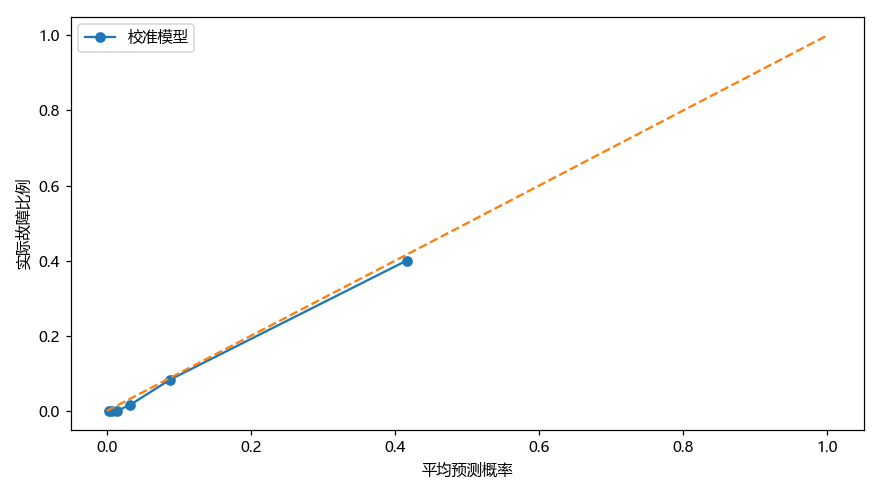

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
模拟故障机制与成本均为教学假设。校准和阈值选择不共享测试集；现实中同设备多次记录必须分组或按时间切分。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。